In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install -q roboflow pyyaml

In [5]:
from google.colab import userdata
from roboflow import Roboflow

# Connect using your existing Colab secret
API_KEY = userdata.get("ROBFLOW_KEY")

rf = Roboflow(api_key=API_KEY)

# Dataset: https://universe.roboflow.com/curbs/curb-jk8ge/dataset/2
project = rf.workspace("curbs").project("curb-jk8ge")

# Explicitly reference version 2
version = project.version(2)

print("Connected successfully!")
print("Project:", project.name)
print("Version:", version.version)



loading Roboflow workspace...
loading Roboflow project...
Connected successfully!
Project: curb
Version: 2


In [6]:

all_results = []

pages = project.search_all(
    class_name="Curb",
    in_dataset=True,
    limit=250,
    fields=["id", "name", "annotations", "split"]
)

for page in pages:
    all_results.extend(page)
    print("Images retrieved so far:", len(all_results))

# Remove duplicate image IDs
unique_results = {
    item["id"]: item for item in all_results
}
all_results = list(unique_results.values())

# Count Curb instances
total_instances = sum(
    item.get("annotations", {})
        .get("classes", {})
        .get("Curb", 0)
    for item in all_results
)

print("\n========== FINAL RESULTS ==========")
print("Unique Curb images:", len(all_results))
print("Total Curb instances:", total_instances)
print("Additional instances needed:", max(0, 400 - total_instances))


Images retrieved so far: 250
Images retrieved so far: 500
Images retrieved so far: 750
Images retrieved so far: 1000
Images retrieved so far: 1250
Images retrieved so far: 1432

========== FINAL RESULTS ==========
Unique Curb images: 1432
Total Curb instances: 1666
Additional instances needed: 0


In [7]:

print("========== SAMPLE ANNOTATIONS ==========")

for item in all_results[:3]:

    details = project.image(item["id"])

    annotation = details.get("annotation") or {}

    print("\nImage:", details.get("name"))
    print("Image ID:", details.get("id"))
    print("Dimensions:", annotation.get("width"), "x",
          annotation.get("height"))
    print("Split:", details.get("split"))

    boxes = annotation.get("boxes", [])

    print("Number of boxes:", len(boxes))

    for box in boxes[:5]:
        print(box)


========== SAMPLE ANNOTATIONS ==========

Image: Ride8_MP4-2.jpg
Image ID: 053hCUW3ASQo1LLyIpXA
Dimensions: 5312 x 2988
Split: train
Number of boxes: 2
{'type': 'polygon', 'label': 'Curb', 'x': '2042.0493', 'y': '2608.1986', 'width': '958.5155', 'height': '756.3712', 'points': [[2222.835433727857, 2236.740570489336], [2306.661992005903, 2251.685488682756], [2326.363522272306, 2310.557292594219], [2521.3070216353854, 2340.167784715761], [2295.511500082775, 2982.5742397079957], [1562.7914922072507, 2986.384185104138], [2197.21335694973, 2230.01302943342]]}
{'type': 'polygon', 'label': 'Curb', 'x': '2601.5989', 'y': '1801.8099', 'width': '151.6567', 'height': '195.4228', 'points': [[2645.9335070177494, 1704.0984498106004], [2659.083172235062, 1705.157785204468], [2661.1588969933164, 1714.5588755627862], [2677.427261970566, 1714.855407671108], [2589.158856043717, 1899.521289390875], [2568.44455449066, 1885.5985956429026], [2559.9207901631703, 1857.0660716752595], [2525.770516529593, 1854.8

In [8]:

from collections import Counter

split_images = Counter()
split_instances = Counter()
annotation_types = Counter()

for item in all_results:

    details = project.image(item["id"])

    split = details.get("split", "unknown")
    boxes = (details.get("annotation") or {}).get("boxes", [])

    split_images[split] += 1

    for box in boxes:
        if box.get("label", "").lower() == "curb":
            split_instances[split] += 1
            annotation_types[box.get("type", "unknown")] += 1

print("========== ORIGINAL SPLIT DISTRIBUTION ==========")

for split in ["train", "valid", "test", "unknown"]:
    print(
        f"{split.upper():8} | "
        f"Images: {split_images[split]:5} | "
        f"Instances: {split_instances[split]:5}"
    )

print("\nAnnotation types:", dict(annotation_types))
print("\nTotal instances:", sum(split_instances.values()))


========== ORIGINAL SPLIT DISTRIBUTION ==========
TRAIN    | Images:   955 | Instances:  1113
VALID    | Images:   270 | Instances:   316
TEST     | Images:   207 | Instances:   237
UNKNOWN  | Images:     0 | Instances:     0

Annotation types: {'polygon': 1662, 'unknown': 4}

Total instances: 1666


In [9]:

import os
import re
import requests
import yaml

from pathlib import Path
from collections import Counter
from PIL import Image
from io import BytesIO

# =====================================================
# CONFIGURATION
# =====================================================

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/curb_400_yolo26"
)

CLASS_ID = 12
SOURCE_LABEL = "Curb"

TARGETS = {
    "train": 240,
    "valid": 60,
    "test": 100
}

# Your complete master class list
MASTER_NAMES = {
    0: "person",
    1: "two_wheeler",
    2: "car",
    3: "auto_rickshaw",
    4: "large_vehicle",
    5: "large_animal",
    6: "dog",
    7: "pothole",
    8: "open_drain",
    9: "speed_breaker",
    10: "stairs_up",
    11: "stairs_down",
    12: "curb_or_step",
    13: "obstacle",
    14: "vendor_stall",
    15: "bench",
    16: "chair",
    17: "door",
    18: "sports_balls",
    19: "traffic_lights",
    20: "other_hazards"
}

# =====================================================
# 1. PREPARE OUTPUT DIRECTORIES
# =====================================================

for split in TARGETS:

    (OUTPUT_DIR / split / "images").mkdir(
        parents=True, exist_ok=True
    )

    (OUTPUT_DIR / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

# =====================================================
# 2. GET CURB INSTANCE COUNT FROM SEARCH RESULTS
# =====================================================

candidates = {
    "train": [],
    "valid": [],
    "test": []
}

seen = set()

for item in all_results:

    image_id = item["id"]

    if image_id in seen:
        continue

    seen.add(image_id)

    split = item.get("split", "").lower()

    if split not in candidates:
        continue

    annotations = item.get("annotations") or {}

    count = (
        annotations.get("classes", {}).get(SOURCE_LABEL, 0)
    )

    if count > 0:

        candidates[split].append({
            "id": image_id,
            "name": item.get("name", str(image_id)),
            "count": count
        })

# =====================================================
# 3. SELECT IMAGES WHILE PRESERVING ORIGINAL SPLITS
# =====================================================

selected = {}

for split, target in TARGETS.items():

    selected[split] = []

    current_count = 0

    # Sort by instance count, descending.
    # This reduces the number of images we need to download.
    ordered = sorted(
        candidates[split],
        key=lambda x: x["count"],
        reverse=True
    )

    for item in ordered:

        if current_count >= target:
            break

        selected[split].append(item)
        current_count += item["count"]

    if current_count < target:
        raise ValueError(
            f"Insufficient {split} instances: "
            f"{current_count}/{target}"
        )

    print(
        f"{split.upper():8} | "
        f"Selected images: {len(selected[split])} | "
        f"Expected instances: {current_count}"
    )

# =====================================================
# 4. DOWNLOAD IMAGES AND CONVERT ANNOTATIONS
# =====================================================

session = requests.Session()

final_counts = Counter()
downloaded_images = Counter()
failed_images = []

for split in TARGETS:

    for item in selected[split]:

        image_id = item["id"]

        try:

            # Retrieve full annotation metadata
            details = project.image(image_id)

            annotation = details.get("annotation") or {}

            boxes = annotation.get("boxes", [])

            curb_boxes = [
                box for box in boxes
                if box.get("label", "").lower() == "curb"
                and all(
                    box.get(key) is not None
                    for key in ["x", "y", "width", "height"]
                )
            ]

            if not curb_boxes:
                raise ValueError("No valid curb annotations")

            # Retrieve original image URL
            image_url = (
                details.get("urls", {}).get("original")
                or details.get("url")
            )

            if not image_url:
                raise ValueError("Image URL not found")

            response = session.get(image_url, timeout=60)
            response.raise_for_status()

            image_bytes = response.content

            # Read actual image dimensions
            image = Image.open(BytesIO(image_bytes))
            image.load()

            img_width, img_height = image.size

            # Preserve original filename, avoiding unsafe characters
            original_name = details.get("name") or item["name"]

            filename = re.sub(
                r"[^A-Za-z0-9_.-]",
                "_",
                original_name
            )

            if not Path(filename).suffix:
                filename += ".jpg"

            image_path = (
                OUTPUT_DIR / split / "images" / filename
            )

            label_path = (
                OUTPUT_DIR / split / "labels" /
                (Path(filename).stem + ".txt")
            )

            # Save original image
            with open(image_path, "wb") as f:
                f.write(image_bytes)

            yolo_annotations = []

            for box in curb_boxes:

                # Roboflow x,y are bounding-box centre coordinates
                x = float(box["x"])
                y = float(box["y"])
                w = float(box["width"])
                h = float(box["height"])

                # Convert to bounding-box corners
                x1 = max(0, x - w / 2)
                y1 = max(0, y - h / 2)
                x2 = min(img_width, x + w / 2)
                y2 = min(img_height, y + h / 2)

                # Skip invalid boxes
                if x2 <= x1 or y2 <= y1:
                    continue

                # Recalculate centre and dimensions after clipping
                xc = ((x1 + x2) / 2) / img_width
                yc = ((y1 + y2) / 2) / img_height
                nw = (x2 - x1) / img_width
                nh = (y2 - y1) / img_height

                yolo_annotations.append(
                    f"{CLASS_ID} "
                    f"{xc:.6f} {yc:.6f} "
                    f"{nw:.6f} {nh:.6f}"
                )

            if not yolo_annotations:
                image_path.unlink(missing_ok=True)
                raise ValueError("All bounding boxes invalid")

            # Save YOLO detection annotations
            with open(label_path, "w") as f:
                f.write("\n".join(yolo_annotations))

            final_counts[split] += len(yolo_annotations)
            downloaded_images[split] += 1

        except Exception as e:

            failed_images.append({
                "id": image_id,
                "split": split,
                "error": str(e)
            })

            print(f"FAILED: {image_id} | {e}")

print("\n========== DOWNLOAD SUMMARY ==========")

for split in TARGETS:

    print(
        f"{split.upper():8} | "
        f"Images: {downloaded_images[split]:4} | "
        f"Instances: {final_counts[split]:4} | "
        f"Target: {TARGETS[split]}"
    )

print("\nFailed images:", len(failed_images))

# =====================================================
# 5. CREATE MASTER-COMPATIBLE DATA.YAML
# =====================================================

data = {
    "path": str(OUTPUT_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(MASTER_NAMES),
    "names": MASTER_NAMES
}

with open(OUTPUT_DIR / "data.yaml", "w") as f:

    yaml.safe_dump(
        data,
        f,
        sort_keys=False
    )

print("\nCreated data.yaml")

# =====================================================
# 6. FINAL REQUIREMENT CHECK
# =====================================================

print("\n========== FINAL REQUIREMENT CHECK ==========")

total = sum(final_counts.values())

for split, target in TARGETS.items():

    status = (
        "PASS"
        if final_counts[split] >= target
        else "FAIL"
    )

    print(
        f"{split.upper():8} | "
        f"{final_counts[split]:4}/{target} | {status}"
    )

print("---------------------------------------------")
print("TOTAL INSTANCES:", total)
print("TOTAL IMAGES:", sum(downloaded_images.values()))

if all(
    final_counts[s] >= TARGETS[s]
    for s in TARGETS
):
    print("\nSUCCESS: All minimum instance requirements met!")
else:
    print("\nWARNING: Some split requirements were not met.")


TRAIN    | Selected images: 110 | Expected instances: 240
VALID    | Selected images: 27 | Expected instances: 61
TEST     | Selected images: 70 | Expected instances: 100

========== DOWNLOAD SUMMARY ==========
TRAIN    | Images:  110 | Instances:  240 | Target: 240
VALID    | Images:   27 | Instances:   61 | Target: 60
TEST     | Images:   70 | Instances:  100 | Target: 100

Failed images: 0

Created data.yaml

========== FINAL REQUIREMENT CHECK ==========
TRAIN    |  240/240 | PASS
VALID    |   61/60 | PASS
TEST     |  100/100 | PASS
---------------------------------------------
TOTAL INSTANCES: 401
TOTAL IMAGES: 207

SUCCESS: All minimum instance requirements met!


In [10]:
from pathlib import Path
from collections import Counter
import yaml

ROOT = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/curb_400_yolo26"
)

instance_counts = Counter()
image_counts = Counter()
class_counts = Counter()
problems = []

for split in ["train", "valid", "test"]:

    image_dir = ROOT / split / "images"
    label_dir = ROOT / split / "labels"

    images = list(image_dir.glob("*"))

    for image in images:

        label = label_dir / (image.stem + ".txt")

        if not label.exists():
            problems.append(f"Missing label: {image.name}")
            continue

        image_counts[split] += 1

        with open(label) as f:
            lines = [x.strip() for x in f if x.strip()]

        for line in lines:

            values = line.split()

            if len(values) != 5:
                problems.append(f"Invalid annotation: {label.name}")
                continue

            cls = int(values[0])

            class_counts[cls] += 1
            instance_counts[split] += 1

            coords = list(map(float, values[1:]))

            if not all(0 <= x <= 1 for x in coords):
                problems.append(f"Invalid normalized coordinates: {label.name}")

print("========== FINAL DATASET REPORT ==========")

for split in ["train", "valid", "test"]:

    print(
        f"{split.upper():8} | "
        f"Images: {image_counts[split]:4} | "
        f"Instances: {instance_counts[split]:4}"
    )

print("\nCLASS DISTRIBUTION")

for cls, count in sorted(class_counts.items()):
    print(f"{cls:3} | {count}")

print("\nTOTAL INSTANCES:", sum(instance_counts.values()))
print("TOTAL IMAGES:", sum(image_counts.values()))

print("\nPROBLEMS:", len(problems))

for p in problems[:20]:
    print(p)

# Verify master class configuration
with open(ROOT / "data.yaml") as f:
    config = yaml.safe_load(f)

assert config["nc"] == 21
assert config["names"][12] == "curb_or_step"

print("\nMASTER YAML CHECK:", "PASS")
print("CLASS ID CHECK:", "PASS" if list(class_counts.keys()) == [12] else "CHECK")


========== FINAL DATASET REPORT ==========
TRAIN    | Images:  110 | Instances:  240
VALID    | Images:   27 | Instances:   61
TEST     | Images:   70 | Instances:  100

CLASS DISTRIBUTION
 12 | 401

TOTAL INSTANCES: 401
TOTAL IMAGES: 207

PROBLEMS: 0

MASTER YAML CHECK: PASS
CLASS ID CHECK: PASS


Total annotations: 401
Total classes: 1


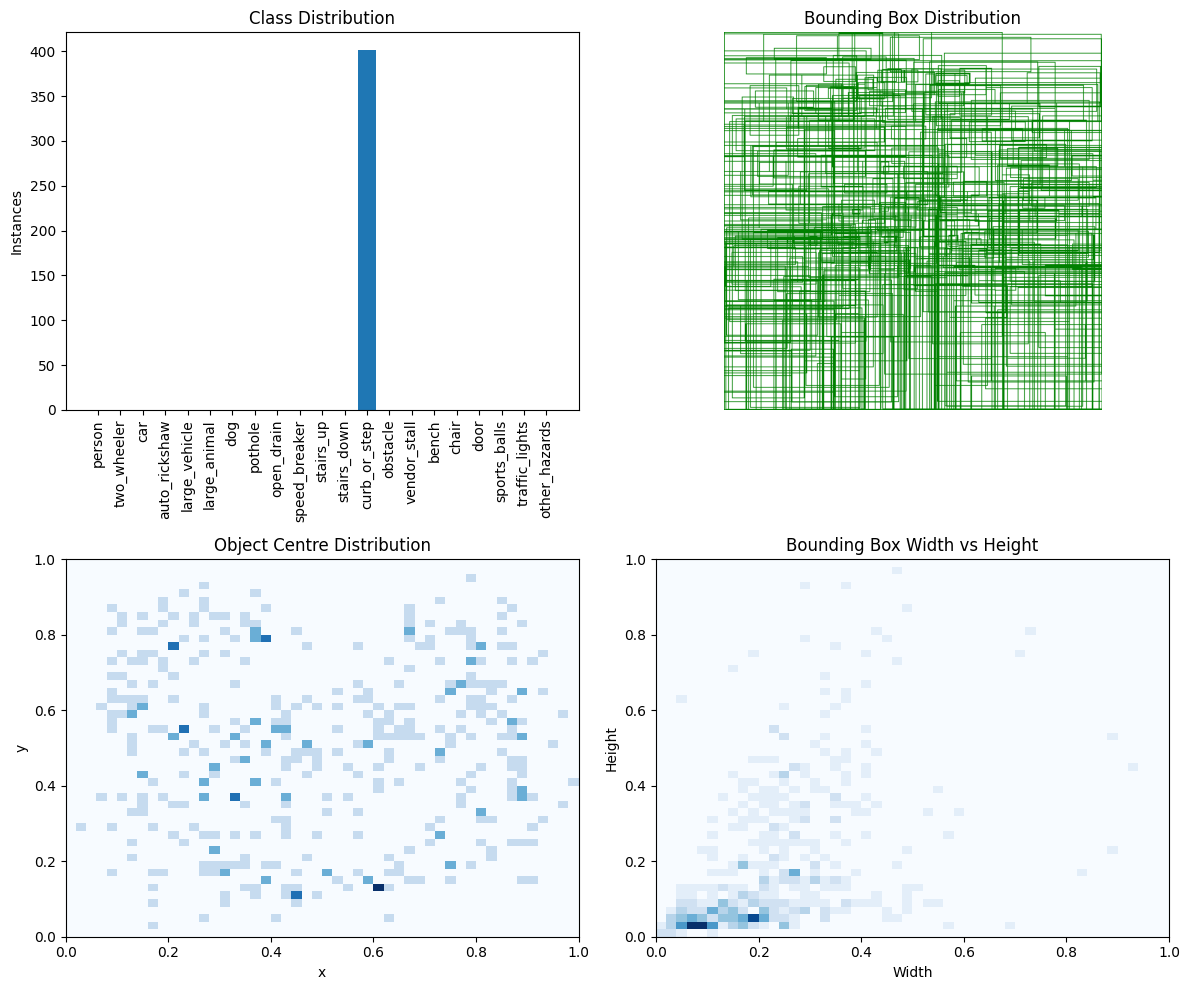

Saved analysis to: /content/drive/MyDrive/Hazard_Detection/raw_datasets/curb_400_yolo26/dataset_analysis.jpg


In [11]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import ImageDraw, Image

# Dataset location
DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/curb_400_yolo26"
)

# Read data.yaml
yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, list):
    names = dict(enumerate(names))

# Find label directories using the dataset splits
base = Path(config.get("path", DATASET_DIR))

if not base.is_absolute():
    base = (yaml_path.parent / base).resolve()

label_dirs = set()

for split in ["train", "val", "valid", "test"]:
    split_path = config.get(split)

    if not split_path:
        continue

    paths = split_path if isinstance(split_path, list) else [split_path]

    for p in paths:
        p = Path(p)

        if not p.is_absolute():
            p = (base / p).resolve()

        parts = list(p.parts)

        if "images" in parts:
            parts[parts.index("images")] = "labels"
            label_dirs.add(Path(*parts))
        else:
            print("Check label folder for:", p)

# Read annotations
classes = []
boxes = []

for label_dir in label_dirs:
    if not label_dir.exists():
        print("Missing:", label_dir)
        continue

    for file in label_dir.rglob("*.txt"):
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) < 5:
                    continue

                cls, x, y, w, h = map(float, values[:5])

                classes.append(int(cls))
                boxes.append([x, y, w, h])

classes = np.array(classes)
boxes = np.array(boxes)

print("Total annotations:", len(classes))
print("Total classes:", len(set(classes)))

# Class distribution
counts = np.bincount(
    classes.astype(int),
    minlength=len(names)
)

# Generate plots
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# 1. Class distribution
ax[0, 0].bar(range(len(names)), counts)

ax[0, 0].set_xticks(range(len(names)))
ax[0, 0].set_xticklabels(
    [names[i] for i in range(len(names))],
    rotation=90
)

ax[0, 0].set_ylabel("Instances")
ax[0, 0].set_title("Class Distribution")

# 2. Bounding box visualization
img = Image.new("RGB", (1000, 1000), "white")
draw = ImageDraw.Draw(img)

for x, y, w, h in boxes[:500]:
    x1 = (x - w/2) * 1000
    y1 = (y - h/2) * 1000
    x2 = (x + w/2) * 1000
    y2 = (y + h/2) * 1000

    draw.rectangle([x1, y1, x2, y2], outline="green", width=2)

ax[0, 1].imshow(img)
ax[0, 1].set_title("Bounding Box Distribution")
ax[0, 1].axis("off")

# 3. Object centre distribution
ax[1, 0].hist2d(
    boxes[:, 0],
    boxes[:, 1],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 0].set_xlabel("x")
ax[1, 0].set_ylabel("y")
ax[1, 0].set_title("Object Centre Distribution")

# 4. Width-height distribution
ax[1, 1].hist2d(
    boxes[:, 2],
    boxes[:, 3],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 1].set_xlabel("Width")
ax[1, 1].set_ylabel("Height")
ax[1, 1].set_title("Bounding Box Width vs Height")

plt.tight_layout()

# Save results
output_path = DATASET_DIR / "dataset_analysis.jpg"

plt.savefig(output_path, dpi=200)
plt.show()

print("Saved analysis to:", output_path)